In [ ]:
import pandas as pd
import numpy as np
import gc

print("1. Loading Datasets...")


train_transaction = pd.read_csv('train_transaction.csv')
train_identity = pd.read_csv('train_identity.csv')


train = pd.merge(train_transaction, train_identity, on='TransactionID', how='left')


del train_transaction, train_identity
gc.collect()

print(f"Dataset Successfully Loaded! Shape: {train.shape}")

1. Loading Datasets...
Dataset Successfully Loaded! Shape: (590540, 434)


In [ ]:
def reduce_mem_usage(df, verbose=True):
    numerics = ['int16', 'int32', 'int64', 'float16', 'float32', 'float64']
    start_mem = df.memory_usage().sum() / 1024**2    
    
    for col in df.columns:
        col_type = df[col].dtype
        
        
        if col_type in numerics or pd.api.types.is_numeric_dtype(df[col]):
            c_min = df[col].min()
            c_max = df[col].max()
            
            if str(col_type)[:3] == 'int':
                if c_min > np.iinfo(np.int8).min and c_max < np.iinfo(np.int8).max:
                    df[col] = df[col].astype(np.int8)
                elif c_min > np.iinfo(np.int16).min and c_max < np.iinfo(np.int16).max:
                    df[col] = df[col].astype(np.int16)
                elif c_min > np.iinfo(np.int32).min and c_max < np.iinfo(np.int32).max:
                    df[col] = df[col].astype(np.int32)
                elif c_min > np.iinfo(np.int64).min and c_max < np.iinfo(np.int64).max:
                    df[col] = df[col].astype(np.int64)  
            else:
                
                if c_min > np.finfo(np.float32).min and c_max < np.finfo(np.float32).max:
                    df[col] = df[col].astype(np.float32)
                else:
                    df[col] = df[col].astype(np.float64)
                    
    end_mem = df.memory_usage().sum() / 1024**2
    if verbose: 
        print(f'Memory usage decreased to {end_mem:.2f} MB ({((start_mem - end_mem) / start_mem)*100:.1f}% reduction)')
    return df


train = reduce_mem_usage(train)

Memory usage decreased to 1044.70 MB (46.6% reduction)


In [ ]:
import numpy as np
import pandas as pd

print("2. Starting Behavioral Feature Engineering...")



card_group = train.groupby('card1')['TransactionAmt']


train['Amt_to_Mean_Card'] = train['TransactionAmt'] / (card_group.transform('mean') + 1e-5)


train['Amt_to_Std_Card'] = (train['TransactionAmt'] - card_group.transform('mean')) / (card_group.transform('std') + 1e-5)


train['is_high_amount_spike'] = (train['Amt_to_Mean_Card'] > 5.0).astype(np.int8)



train['Hour_of_Day'] = ((train['TransactionDT'] // 3600) % 24).astype(np.int8)
train['Day_of_Week'] = ((train['TransactionDT'] // (3600 * 24)) % 7).astype(np.int8)




train['is_email_match'] = (train['P_emaildomain'] == train['R_emaildomain']).astype(np.int8)


train['has_identity_data'] = train['DeviceType'].notnull().astype(np.int8)


print("Behavioral Features Created Successfully!")
print(f"New Shape: {train.shape}")

2. Starting Behavioral Feature Engineering...
Behavioral Features Created Successfully!
New Shape: (590540, 441)


In [ ]:
print("3. Preprocessing Categorical Features...")


train['P_emaildomain'] = train['P_emaildomain'].astype(str).str.lower()
train['R_emaildomain'] = train['R_emaildomain'].astype(str).str.lower()


cat_cols = [col for col in train.columns if train[col].dtype == 'object' or col.startswith('card') or col.startswith('addr')]


for col in cat_cols:
    train[col] = train[col].astype('category')

print("Categorical Encoding Ready!")

3. Preprocessing Categorical Features...
Categorical Encoding Ready!


In [ ]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import joblib

print("4. Preparing Features and Target...")


y = train['isFraud']


drop_cols = ['isFraud', 'TransactionID', 'TransactionDT']
X = train.drop(columns=drop_cols)

print(f"Features Matrix Shape: {X.shape}")
print(f"Target Distribution: Fraud={y.sum()} ({y.mean()*100:.2f}%) | Legit={(y==0).sum()}")

4. Preparing Features and Target...
Features Matrix Shape: (590540, 431)
Target Distribution: Fraud=20663 (3.50%) | Legit=569877


In [ ]:

for col in X.columns:
    if X[col].dtype == 'object' or str(X[col].dtype) == 'string':
        X[col] = X[col].astype('category')

print("All text features converted to 'category' dtype successfully!")

All text features converted to 'category' dtype successfully!


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

print("Fixing categorical features for LightGBM...")


cat_cols = [col for col in X.columns if X[col].dtype == 'object' or str(X[col].dtype) == 'string' or X[col].dtype.name == 'category']


for col in cat_cols:
    X[col] = X[col].astype(str) 
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    X[col] = encoder.fit_transform(X[[col]])

print(f"Successfully encoded {len(cat_cols)} categorical columns into numeric codes!")

Fixing categorical features for LightGBM...
Successfully encoded 8 categorical columns into numeric codes!


In [25]:
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("1. Re-building X and y directly from train dataframe...")
y = train['isFraud']
X = train.drop(columns=['isFraud', 'TransactionID', 'TransactionDT']).copy()

# 2. تحويل كاسح لجميع الأعمدة النصية / الأجسام بدون الاعتماد على نوع الـ dtype
print("2. Force encoding all non-numeric features to int32...")
converted_count = 0
for col in X.columns:
    # إذا لم يكن العمود رقمي بحت (float أو int)، قم بتحويله أوتوماتيكياً
    if not pd.api.types.is_numeric_dtype(X[col]):
        X[col], _ = pd.factorize(X[col].astype(str))
        X[col] = X[col].astype('int32')
        converted_count += 1

print(f"Successfully converted {converted_count} non-numeric columns into clean int32 features.")

# 3. إعداد التقسيم المتقاطع والتدريب
print("\n3. Starting LightGBM Training with Stratified K-Fold...")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = np.zeros(len(X))
models = []

lgb_params = {
    'objective': 'binary',
    'metric': 'auc',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 64,
    'max_depth': -1,
    'feature_fraction': 0.8,
    'bagging_fraction': 0.8,
    'bagging_freq': 1,
    'scale_pos_weight': 25,
    'n_jobs': -1,
    'random_state': 42,
    'verbose': -1
}

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
    
    model = lgb.LGBMClassifier(**lgb_params, n_estimators=1000)
    
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    
    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds
    models.append(model)
    
    fold_auc = roc_auc_score(y_val, val_preds)
    print(f"Fold {fold + 1} ROC-AUC: {fold_auc:.5f}")

overall_auc = roc_auc_score(y, oof_preds)
print(f"\n---> Overall Out-of-Fold ROC-AUC Score: {overall_auc:.5f} <---")

1. Re-building X and y directly from train dataframe...
2. Force encoding all non-numeric features to int32...
Successfully converted 31 non-numeric columns into clean int32 features.

3. Starting LightGBM Training with Stratified K-Fold...
Fold 1 ROC-AUC: 0.96486
Fold 2 ROC-AUC: 0.96783
Fold 3 ROC-AUC: 0.96613
Fold 4 ROC-AUC: 0.96716
Fold 5 ROC-AUC: 0.96599

---> Overall Out-of-Fold ROC-AUC Score: 0.96637 <---


In [26]:
# فحص الـ AUC على بيانات التدريب للـ Fold الأول لمعرفة الفجوة (Generalization Gap)
train_idx, val_idx = next(skf.split(X, y))
train_preds = models[0].predict_proba(X.iloc[train_idx])[:, 1]
val_preds = models[0].predict_proba(X.iloc[val_idx])[:, 1]

train_auc = roc_auc_score(y.iloc[train_idx], train_preds)
val_auc = roc_auc_score(y.iloc[val_idx], val_preds)

print(f"Train ROC-AUC: {train_auc:.5f}")
print(f"Validation ROC-AUC: {val_auc:.5f}")
print(f"Difference (Gap): {train_auc - val_auc:.5f}")

Train ROC-AUC: 0.99821
Validation ROC-AUC: 0.96486
Difference (Gap): 0.03335


In [27]:
import joblib

print("Saving trained model artifacts...")

# حفظ النموذج الأول (أو النموذج ذو أعلى أداء) مع قائمة الخصائص
model_payload = {
    'model': models[0],
    'features': list(X.columns)
}

joblib.dump(model_payload, 'fraud_detection_lgbm.joblib')
print("Artifact saved as 'fraud_detection_lgbm.joblib'")

Saving trained model artifacts...
Artifact saved as 'fraud_detection_lgbm.joblib'


In [ ]:
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel
import joblib
import pandas as pd
import numpy as np

app = FastAPI(
    title="IEEE-CIS Fraud Detection API",
    description="Enterprise Real-Time Fraud Detection Service using LightGBM",
    version="1.0.0"
)


try:
    artifact = joblib.load('fraud_detection_lgbm.joblib')
    model = artifact['model']
    feature_names = artifact['features']
    print("Model payload loaded successfully!")
except Exception as e:
    print(f"Error loading model artifact: {e}")

class TransactionRequest(BaseModel):
    features: dict

@app.get("/")
def health_check():
    return {"status": "online", "message": "Fraud Detection API is active"}

@app.post("/predict")
def predict_transaction(payload: TransactionRequest):
    try:
        
        input_data = pd.DataFrame([payload.features])
        
        
        for col in feature_names:
            if col not in input_data.columns:
                input_data[col] = np.nan
                
        input_data = input_data[feature_names]

        
        prob = float(model.predict_proba(input_data)[:, 1][0])
        is_fraud = bool(prob > 0.5)

        return {
            "is_fraud": is_fraud,
            "fraud_probability": round(prob, 4),
            "risk_level": "High Risk" if is_fraud else "Low Risk"
        }
    except Exception as e:
        raise HTTPException(status_code=500, detail=str(e))

Model payload loaded successfully!



LOADING AND PREPROCESSING DATA
Loading training transaction data...
Loading training identity data...
Train transactions shape: (590540, 394)
Train identity shape: (144233, 41)
Merged data shape: (590540, 434)
Missing values after merge:
TransactionID        0
isFraud              0
TransactionDT        0
TransactionAmt       0
ProductCD            0
card1                0
card2             8933
card3             1565
card4             1577
card5             4259
dtype: int64

STARTING DATA PREPROCESSING
Numerical features (402): ['TransactionID', 'TransactionDT', 'TransactionAmt', 'card1', 'card2', 'card3', 'card5', 'addr1', 'addr2', 'dist1']...
Categorical features (31): ['ProductCD', 'card4', 'card6', 'P_emaildomain', 'R_emaildomain', 'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9', 'id_12', 'id_15', 'id_16', 'id_23', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType', 'DeviceInfo']
Time features engineered: hour_of_

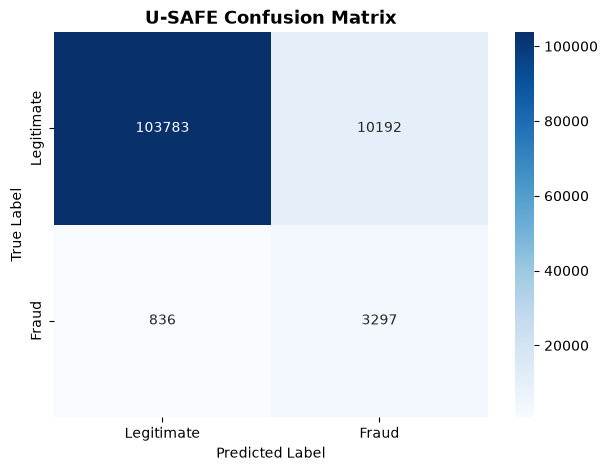

In [ ]:
from train import ModelTrainer
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


trainer = ModelTrainer()
df = trainer.load_and_preprocess_data()
X_train, X_val, X_test, y_train, y_val, y_test = trainer.split_data(df)


model = trainer.load_model()
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba >= 0.5).astype(int)


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legitimate', 'Fraud'],
            yticklabels=['Legitimate', 'Fraud'])

plt.title('U-SAFE Confusion Matrix', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

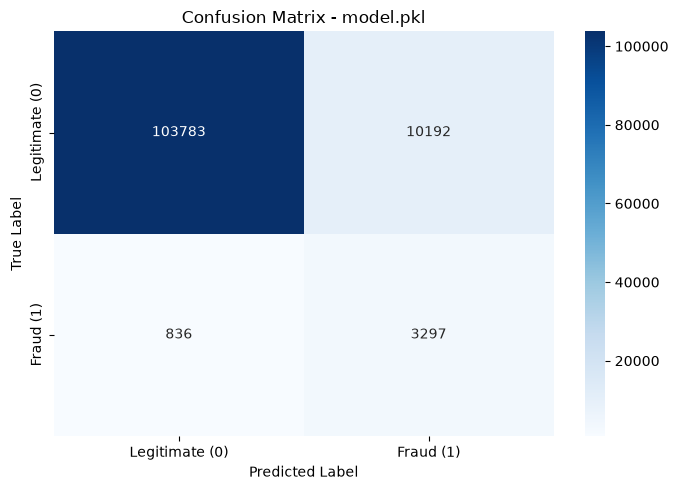

              precision    recall  f1-score   support

  Legitimate       0.99      0.91      0.95    113975
       Fraud       0.24      0.80      0.37      4133

    accuracy                           0.91    118108
   macro avg       0.62      0.85      0.66    118108
weighted avg       0.97      0.91      0.93    118108



In [ ]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


model = joblib.load('models/model.pkl')


y_probs = model.predict(X_test)  


y_pred = (y_probs >= 0.5).astype(int)


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Legitimate (0)', 'Fraud (1)'],
            yticklabels=['Legitimate (0)', 'Fraud (1)'])

plt.title('Confusion Matrix - model.pkl')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=['Legitimate', 'Fraud']))

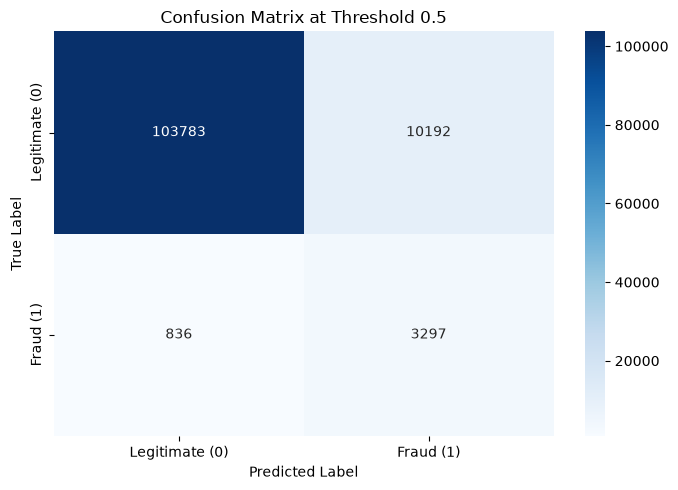

--- Classification Report at Threshold 0.5 ---
              precision    recall  f1-score   support

  Legitimate       0.99      0.91      0.95    113975
       Fraud       0.24      0.80      0.37      4133

    accuracy                           0.91    118108
   macro avg       0.62      0.85      0.66    118108
weighted avg       0.97      0.91      0.93    118108



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report


optimal_threshold = 0.50
y_pred_opt = (y_probs >= optimal_threshold).astype(int)


cm_opt = confusion_matrix(y_test, y_pred_opt)

س
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_opt,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Legitimate (0)', 'Fraud (1)'],
    yticklabels=['Legitimate (0)', 'Fraud (1)'],
)

plt.title(f'Confusion Matrix at Threshold {optimal_threshold}')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()


print(f'--- Classification Report at Threshold {optimal_threshold} ---')
print(
    classification_report(
        y_test, y_pred_opt, target_names=['Legitimate', 'Fraud']
    )
)